# Importação de Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

from ucimlrepo import fetch_ucirepo # Importação de Dados
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

# 1) Preparação dos Dados

In [2]:
rt_iot2022 = fetch_ucirepo(id=942)

# Seperação das features com a coluna Target
x = rt_iot2022.data.features
y = rt_iot2022.data.targets

df_rt_iot2022 = pd.concat([x, y], axis=1)
target_column = y.columns[0]

print(f'Shape: {df_rt_iot2022.shape}')
print(f'Target: {target_column}\n')

Shape: (123117, 84)
Target: Attack_type



#### 1.1) Remoção de Colunas e Duplicadas

In [3]:
# Colunas Constantes
constant_columns = [c for c in df_rt_iot2022.columns if df_rt_iot2022[c].nunique() <= 1]
df_rt_iot2022 = df_rt_iot2022.drop(columns=constant_columns, axis=1)

# Colunas Redundantes
redundant_columns = ['bwd_bulk_packets', 'fwd_subflow_bytes', 'fwd_pkts_payload.tot', 'flow_iat.min', 'flow_iat.max', 'flow_iat.avg', 'flow_iat.tot', 'bwd_data_pkts_tot', 'bwd_header_size_min', 'fwd_bulk_rate', 'fwd_bulk_packets', 'active.min', 'active.avg', 'active.tot', 'idle.max', 'fwd_iat.avg', 'bwd_iat.min', 'bwd_pkts_payload.avg', 'bwd_pkts_payload.std', 'bwd_pkts_payload.max', 'fwd_iat.max', 'fwd_iat.min', 'fwd_iat.tot', 'bwd_init_window_size', 'bwd_iat.std', 'fwd_iat.std', 'bwd_PSH_flag_count', 'fwd_pkts_payload.min', 'bwd_iat.max', 'bwd_iat.tot', 'bwd_iat.avg', 'fwd_header_size_max', 'flow_ACK_flag_count', 'bwd_pkts_per_sec', 'payload_bytes_per_second', 'idle.tot', 'fwd_subflow_pkts']

df_rt_iot2022 = df_rt_iot2022.drop(columns=redundant_columns, axis=1)

print(f'Shape: {df_rt_iot2022.shape}')
print(f'Target: {target_column}\n')

Shape: (123117, 46)
Target: Attack_type



In [4]:
# Remoção de Duplicadas
df_rt_iot2022 = df_rt_iot2022.drop_duplicates().reset_index(drop=True)

print(f'Shape: {df_rt_iot2022.shape}')
print(f'Target: {target_column}\n')

Shape: (117922, 46)
Target: Attack_type



# 2) Treinamento do Modelo

#### 2.1) Separação dos Dados

In [5]:
X = df_rt_iot2022.drop(columns=[target_column], axis=1)
y = df_rt_iot2022[target_column]

In [6]:
x_encoded = pd.get_dummies(data=X, columns=['proto', 'service'], drop_first=True, dtype=int)

le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(x_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

#### 2.2) Aplicação do Modelo

In [8]:
rf_model = RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced_subsample', n_jobs=-1)

rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [9]:
y_test_pred = rf_model.predict(X_test)

In [10]:
print(f"Acurácia: {accuracy_score(y_true=y_test, y_pred=y_test_pred)}")
print(f"Acurácia Balanceada: {balanced_accuracy_score(y_true=y_test, y_pred=y_test_pred)}")

print(f"Macro F1-Score: {f1_score(y_true=y_test, y_pred=y_test_pred, average='macro')}")
print(f"Weighted F1-Score: {f1_score(y_true=y_test, y_pred=y_test_pred, average='weighted')}\n")

print('Relatório de Classificação')
print(classification_report(y_test, y_test_pred, zero_division=0, target_names=le.classes_))

Acurácia: 0.9983040067839729
Acurácia Balanceada: 0.992790698559202
Macro F1-Score: 0.9893169179756575
Weighted F1-Score: 0.9983054991328508

Relatório de Classificação
                            precision    recall  f1-score   support

            ARP_poisioning       0.99      0.99      0.99      1525
            DDOS_Slowloris       0.99      0.99      0.99       107
             DOS_SYN_Hping       1.00      1.00      1.00     18018
              MQTT_Publish       1.00      1.00      1.00       828
Metasploit_Brute_Force_SSH       0.88      1.00      0.93         7
             NMAP_FIN_SCAN       1.00      1.00      1.00         6
         NMAP_OS_DETECTION       1.00      1.00      1.00       400
             NMAP_TCP_scan       1.00      1.00      1.00       200
             NMAP_UDP_SCAN       1.00      0.99      1.00       517
       NMAP_XMAS_TREE_SCAN       1.00      1.00      1.00       402
               Thing_Speak       0.99      0.99      0.99      1531
              

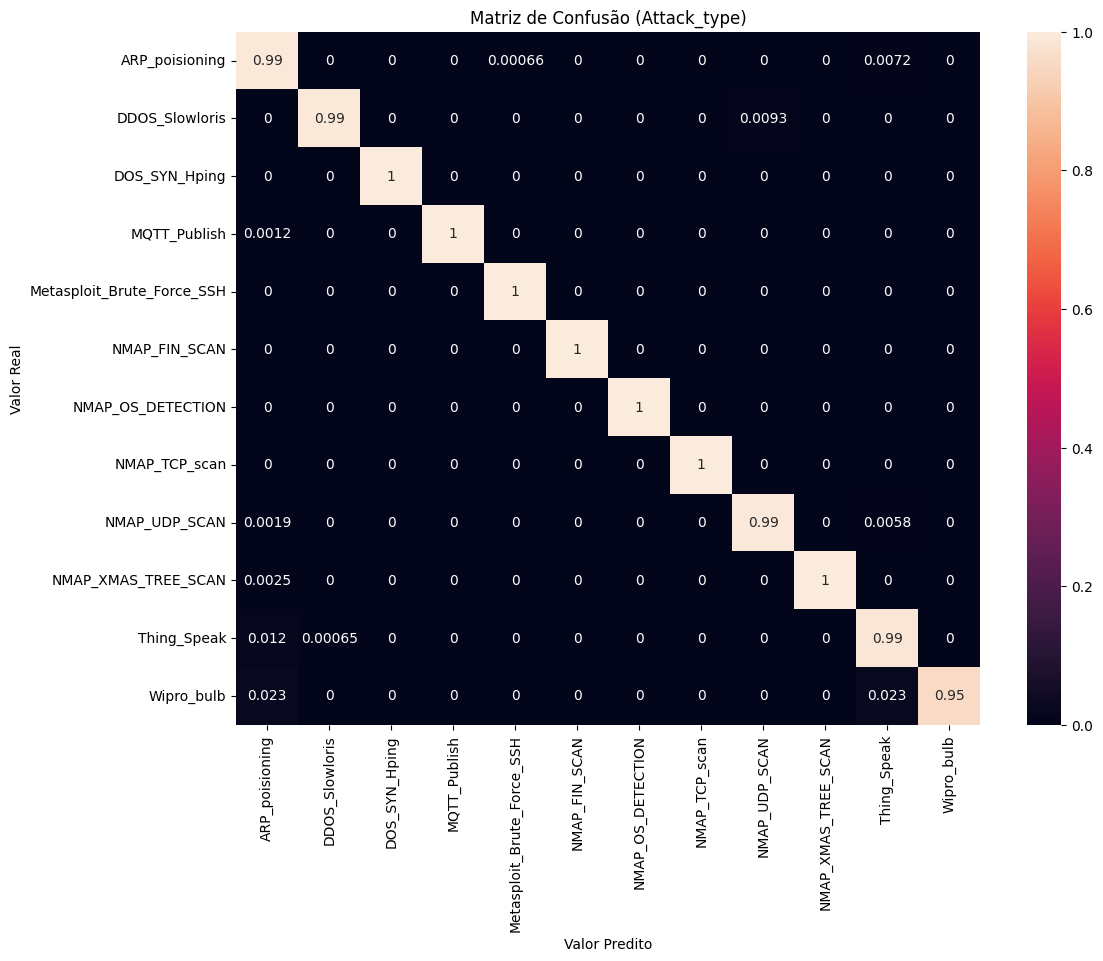

In [11]:
cm = confusion_matrix(y_true=y_test, y_pred=y_test_pred, normalize="true")

fig, axes = plt.subplots(figsize=(12, 9))
sns.heatmap(
    cm, annot=True, ax=axes,
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.title(f"Matriz de Confusão ({target_column})")
axes.set_xlabel("Valor Predito")
axes.set_ylabel("Valor Real")
plt.show()

#### 2.3) Avaliação de Importâncias

In [12]:
df_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

print("Colunas por Grau de Importância")
print(df_importances, "\n")

print(f'Soma das 10 colunas mais importantes: {df_importances.head(10).sum()}')
print(f'Soma das 30 colunas menos importantes: {df_importances.tail(30).sum()}')


Colunas por Grau de Importância
id.resp_p                5.176790e-02
fwd_last_window_size     4.675310e-02
fwd_PSH_flag_count       4.308254e-02
flow_pkts_per_sec        4.275292e-02
fwd_header_size_min      4.253189e-02
flow_pkts_payload.max    4.108769e-02
fwd_URG_flag_count       4.090331e-02
fwd_pkts_payload.avg     4.042357e-02
fwd_pkts_payload.max     3.930682e-02
fwd_pkts_per_sec         3.777525e-02
flow_pkts_payload.avg    3.485867e-02
flow_pkts_payload.tot    3.341631e-02
fwd_init_window_size     3.305901e-02
flow_FIN_flag_count      3.226251e-02
active.max               3.174047e-02
fwd_header_size_tot      2.928224e-02
service_mqtt             2.873064e-02
flow_duration            2.573970e-02
id.orig_p                2.122734e-02
fwd_data_pkts_tot        1.961573e-02
flow_pkts_payload.std    1.830345e-02
service_http             1.802379e-02
flow_SYN_flag_count      1.744702e-02
flow_pkts_payload.min    1.741667e-02
service_ssh              1.575840e-02
bwd_subflow_bytes 

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(rf_model, x_encoded, y_encoded, cv=cv, scoring="f1_macro", n_jobs=-1)
print(f"F1-Macro: {scores.mean()} | {scores.std()}")

F1-Macro: 0.9775745706775301 | 0.005929047197065241
